# Interpreting the Sinhala Q&A Benchmark

**The benchmark.** 302 Sinhala items per model, in two subsets that are scored
separately and never averaged together:

| Subset | n | What it tests | Scored by |
|---|---|---|---|
| `short_answer` | 226 | Extract a correct answer from the passage | Exact Match, Token F1, chrF, chrF3 |
| `unanswerable` | 76 | Decline when the passage does not contain the answer | No-answer EM |

Every item also carries one human label: **Supported**, **Unsupported** (hallucinated),
**Correct Refusal**, **False Refusal** (over-refusal), or **Degenerated Repetition
Output** (the model never finished generating — a generation failure, not a
hallucination, and counted separately from one).



In [ ]:
# --- setup -----------------------------------------------------------------
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt


PROJECT_OVERRIDE = ""        

PROJECT = None
for _c in ([Path(PROJECT_OVERRIDE)] if PROJECT_OVERRIDE else
           [Path.cwd(), Path.cwd().parent, Path("/content")]):
    if (_c / "evaluate_models.py").exists():
        PROJECT = _c
        break

if PROJECT is None:
    raise FileNotFoundError(
    )

sys.path.insert(0, str(PROJECT))
print(f"PROJECT = {PROJECT}")

from evaluate_models import (
    read_sheet, normalise, model_name_from,
    ST_SHORT, ST_UNANS, HUMAN_LABELS,
    LBL_SUPPORTED, LBL_UNSUPPORTED, LBL_CORRECT_REFUSAL, LBL_FALSE_REFUSAL,
    LBL_DEGENERATE,
)

RESULTS_DIR = PROJECT / "model_results"

# --- palette: validated default, light chart surface ------------------------
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
SERIES_1 = "#2a78d6"                                    # categorical slot 1
GOOD, WARNING, SERIOUS, CRITICAL = "#0ca30c", "#fab219", "#ec835a", "#d03b3b"

OUTCOME_COLOR = {
    LBL_SUPPORTED: GOOD, LBL_CORRECT_REFUSAL: GOOD,
    LBL_FALSE_REFUSAL: WARNING, LBL_DEGENERATE: SERIOUS, LBL_UNSUPPORTED: CRITICAL,
}

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE, "figure.dpi": 120,
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "legend.frameon": False,
})


def style(ax, title=None, xlabel=None, ylabel=None, axis="y"):
    """Recessive chrome: grid on the value axis only."""
    ax.grid(axis=axis)
    ax.set_axisbelow(True)
    if title:
        ax.set_title(title, color=INK, fontsize=11.5, pad=12, loc="left")
    ax.set_xlabel(xlabel or "", fontsize=9.5)
    ax.set_ylabel(ylabel or "", fontsize=9.5)
    return ax


def short_name(model):
    return model.split("/")[-1]


def label_points(ax, xs, ys, labels, fontsize=8.5):
    from matplotlib.transforms import Bbox

    fig = ax.figure
    fig.canvas.draw()

    # Seed the occupied list with the markers, so a label never lands on a dot.
    placed = []
    for px, py in zip(xs, ys):
        mx, my = ax.transData.transform((px, py))
        placed.append(Bbox.from_bounds(mx - 7, my - 7, 14, 14))

    offsets = [(0, 11), (0, -17), (12, 4), (-12, 4), (0, 22), (0, -28),
               (15, -13), (-15, -13), (0, 33), (0, -39), (26, 4), (-26, 4)]
    order = np.argsort(-np.asarray(ys))          # top-down keeps leaders clear
    for i in order:
        for dx, dy in offsets:
            ha = "center" if dx == 0 else ("left" if dx > 0 else "right")
            ann = ax.annotate(labels[i], (xs[i], ys[i]), xytext=(dx, dy),
                              textcoords="offset points", ha=ha, va="center",
                              fontsize=fontsize, color=INK_2, zorder=5)
            fig.canvas.draw()
            box = ann.get_window_extent()
            if not any(box.overlaps(b) for b in placed):
                placed.append(box.expanded(1.05, 1.2))
                if abs(dy) > 20 or abs(dx) > 20:     # far enough to need a leader
                    ax.annotate("", (xs[i], ys[i]),
                                xytext=(dx * 0.6, dy * 0.6),
                                textcoords="offset points",
                                arrowprops=dict(arrowstyle="-", color=AXIS,
                                                linewidth=0.7, shrinkA=0, shrinkB=4),
                                zorder=2)
                break
            ann.remove()
        else:                                     # nowhere free - place anyway
            placed.append(ax.annotate(labels[i], (xs[i], ys[i]), xytext=(0, 11),
                                      textcoords="offset points", ha="center",
                                      fontsize=fontsize, color=INK_2, zorder=5
                                      ).get_window_extent())

PROJECT = c:\Users\User\Documents\Last Year\Sem 07\NLP\Research\Result


In [ ]:
# --- load the generated sheets and the raw annotations ----------------------
comparison = pd.read_csv(RESULTS_DIR / "all_models_results.csv")

per_model = {}       # model -> per-metric result table
for path in sorted(RESULTS_DIR.glob("*/*_results.csv")):
    tbl = pd.read_csv(path)
    per_model[tbl["model"].iat[0]] = tbl

raw = {}             # model -> normalised item-level annotations
for path in sorted(PROJECT.glob("*.csv")):
    sheet = read_sheet(path)
    try:
        raw[model_name_from(sheet, path)] = normalise(sheet)
    except ValueError:
        continue     # not an annotation sheet

MODELS = list(comparison["model"])
N_MODELS = len(MODELS)

FOCUS = MODELS[0]

print(f"{N_MODELS} model(s) loaded. Profiling FOCUS = {FOCUS}")
print(f"item-level sheets: {len(raw)}")

13 model(s) loaded. Profiling FOCUS = gemini-pro-agent
item-level sheets: 13


## 1. Main results table

The paper's Table 1. Each column is scored on the subset where it is valid, so the
`No-ans EM` column describes 76 items and the overlap metrics describe 226.

In [3]:
COLS = {
    "model": "Model",
    "exact_match": "EM", "token_f1": "Token F1", "chrf": "chrF", "chrf3": "chrF3",
    "noans_em": "No-ans EM",
    "hallucination_rate": "Halluc %", "degenerate_rate": "Degen %",
    "false_refusal_rate": "False ref %", "correct_refusal_rate": "Correct ref %",
    "human_accuracy": "Human acc %",
}
table_1 = comparison[list(COLS)].rename(columns=COLS)
display(table_1.style.format(precision=2, subset=table_1.columns[1:])
        .hide(axis="index")
        .set_caption("Table 1 — EM/F1/chrF on short_answer (n=226); "
                     "No-ans EM on unanswerable (n=76); rates from human labels"))

detail = per_model[FOCUS].copy()
lo = pd.to_numeric(detail["ci95_low"], errors="coerce")
hi = pd.to_numeric(detail["ci95_high"], errors="coerce")
detail["value [95% CI]"] = [
    f"{v:.2f}" if pd.isna(a) else f"{v:.2f}  [{a:.2f}, {b:.2f}]"
    for v, a, b in zip(detail["value"], lo, hi)
]
display(detail[["metric", "subset", "value [95% CI]", "n"]]
        .style.hide(axis="index").set_caption(f"Table 2 — {FOCUS}, full metric set"))

Model,EM,Token F1,chrF,chrF3,No-ans EM,Halluc %,Degen %,False ref %,Correct ref %,Human acc %
gemini-pro-agent,25.22,54.63,62.40,69.93,98.68,1.77,0.00,2.65,98.68,96.36
meta-llama/llama-4-maverick,23.01,51.10,58.05,66.06,72.37,3.10,0.00,0.88,72.37,90.07
deepseek/deepseek-v4-pro-0813,22.67,49.83,57.80,65.40,94.74,2.65,0.00,4.87,94.74,93.05
gpt-5.5,15.49,47.63,58.96,67.26,85.53,4.87,0.00,0.44,86.84,92.72
deepseek/deepseek-v4-flash-0731,22.32,45.86,52.50,60.08,94.74,3.10,0.00,6.64,96.05,91.72
gemini-3.6-flash-high,11.95,44.48,54.09,61.50,100.00,1.33,0.00,7.52,100.00,93.38
qwen/qwen3.5-9b,17.26,41.85,49.39,56.63,67.11,7.96,0.00,8.85,82.89,83.11
qwen/qwen3.5-27b,16.37,41.83,48.16,55.31,100.00,2.65,0.00,15.93,100.00,86.09
claude-opus-4-6-thinking,10.18,36.84,48.71,56.18,82.89,2.21,0.00,0.44,96.05,97.02
meta-llama/llama-3.1-70b-instruct,19.47,33.26,36.54,43.80,31.58,41.15,0.00,0.00,31.58,51.99


metric,subset,value [95% CI],n
Exact Match (%),short_answer,"25.22 [19.91, 30.97]",226
Token F1 (%),short_answer,"54.63 [50.11, 59.12]",226
chrF,short_answer,"62.40 [58.04, 66.49]",226
chrF3,short_answer,"69.93 [65.82, 74.05]",226
No-answer EM (%),unanswerable,"98.68 [96.05, 100.00]",76
Supported (n),short_answer,216.00,226
Unsupported (n),short_answer,4.00,226
False Refusal (n),short_answer,6.00,226
Correct Refusal (n),unanswerable,75.00,76
Degenerated Repetition Output (n),overall,0.00,302


## 2. How the models rank


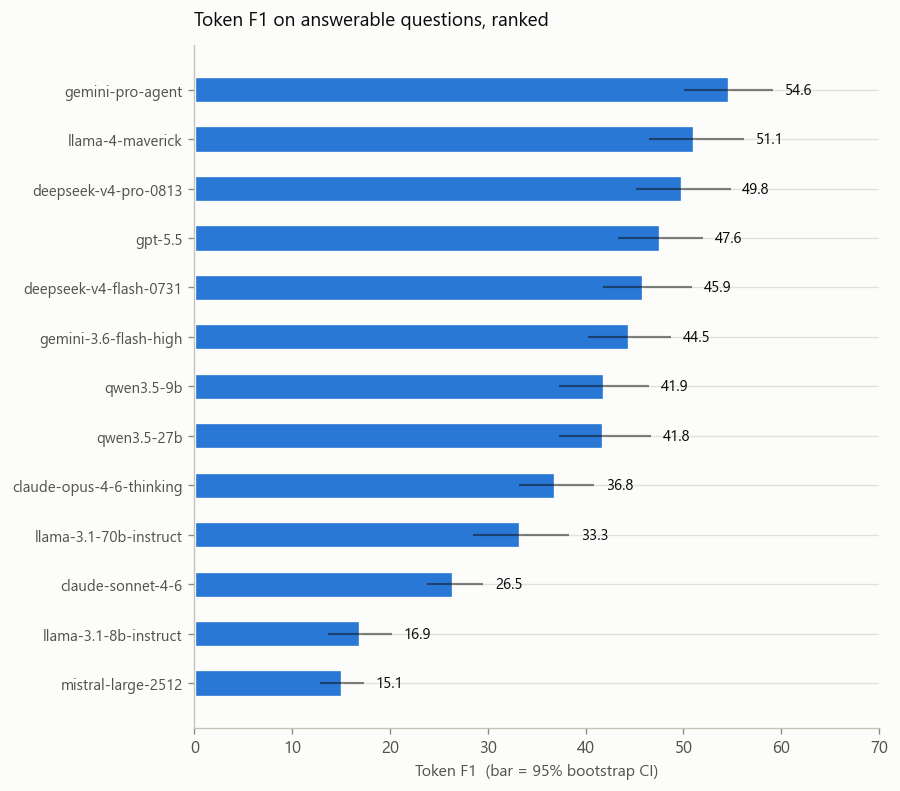

Reading: gemini-pro-agent leads at 54.6, but 2 model(s) fall inside its confidence interval —
llama-4-maverick, gemini-pro-agent.
Those positions are not separated at this sample size and should be reported as a tied band.


In [ ]:
# --- Figure 1: ranked answer quality, with 95% CIs --------------------------
rank = comparison.sort_values("token_f1")
ci = pd.concat(per_model.values())
ci = ci[ci["metric"].eq("Token F1 (%)")].set_index("model")
lo = pd.to_numeric(ci.loc[rank["model"], "ci95_low"], errors="coerce").to_numpy()
hi = pd.to_numeric(ci.loc[rank["model"], "ci95_high"], errors="coerce").to_numpy()
val = rank["token_f1"].to_numpy()
y = np.arange(N_MODELS)

fig, ax = plt.subplots(figsize=(7.6, 0.40 * N_MODELS + 1.5))
ax.barh(y, val, height=0.55, color=SERIES_1, edgecolor=SURFACE, linewidth=2)
ax.hlines(y, lo, hi, color=INK, linewidth=1.3, alpha=0.5, zorder=3)
for yi, v, h in zip(y, val, hi):
    ax.annotate(f"{v:.1f}", (h, yi), xytext=(7, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK)          # after the CI, not on it
ax.set_yticks(y, [short_name(m) for m in rank["model"]], fontsize=9)
ax.set_xlim(0, max(70, np.nanmax(hi) * 1.18))
style(ax, "Token F1 on answerable questions, ranked",
      "Token F1  (bar = 95% bootstrap CI)", axis="x")
plt.tight_layout(); plt.show()

top = rank.iloc[-1]
ties = rank[rank["token_f1"] >= pd.to_numeric(
    ci.loc[top["model"], "ci95_low"], errors="coerce")]


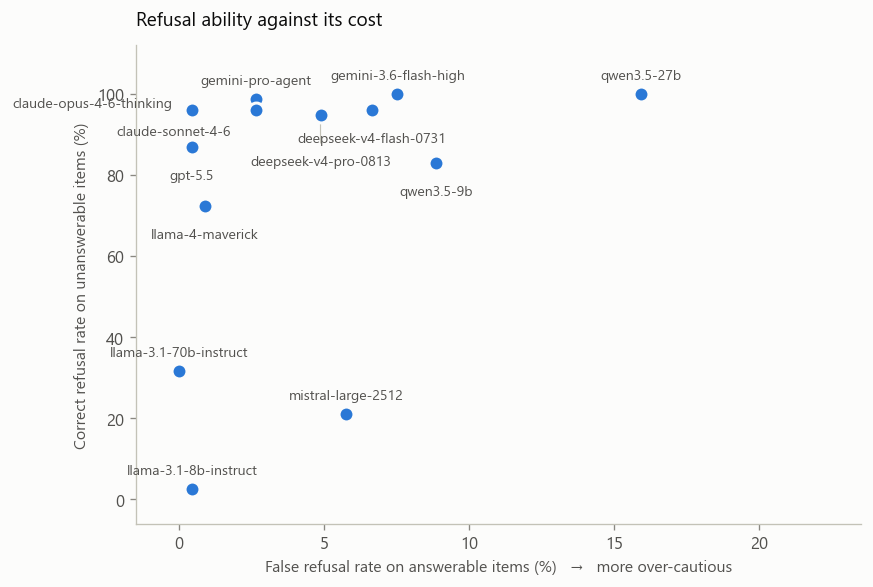

Reading: up and to the LEFT is better — declining the unanswerable questions without also
declining answerable ones. claude-opus-4-6-thinking is closest to that corner (96% correct refusal at 0.4% false refusal).
A model high on both axes is not careful, only reluctant; one low on both simply answers everything.


In [ ]:
# --- Figure 2: refusal ability against its cost -----------------------------
# Both axes come from the human labels, which are the authoritative signal.
fig, ax = plt.subplots(figsize=(7.4, 5.0))
ax.scatter(comparison["false_refusal_rate"], comparison["correct_refusal_rate"],
           s=80, color=SERIES_1, edgecolor=SURFACE, linewidth=1.8, zorder=3)
ax.set_xlim(-1.5, comparison["false_refusal_rate"].max() * 1.35 + 2)
ax.set_ylim(-6, 112)
label_points(ax, comparison["false_refusal_rate"].to_numpy(),
             comparison["correct_refusal_rate"].to_numpy(),
             [short_name(m) for m in comparison["model"]])
style(ax, "Refusal ability against its cost",
      "False refusal rate on answerable items (%)   →   more over-cautious",
      "Correct refusal rate on unanswerable items (%)", axis="both")
plt.tight_layout(); plt.show()

best = comparison.loc[(comparison["correct_refusal_rate"]
                       - 2 * comparison["false_refusal_rate"]).idxmax()]


## 3. Where the automatic metrics mislead

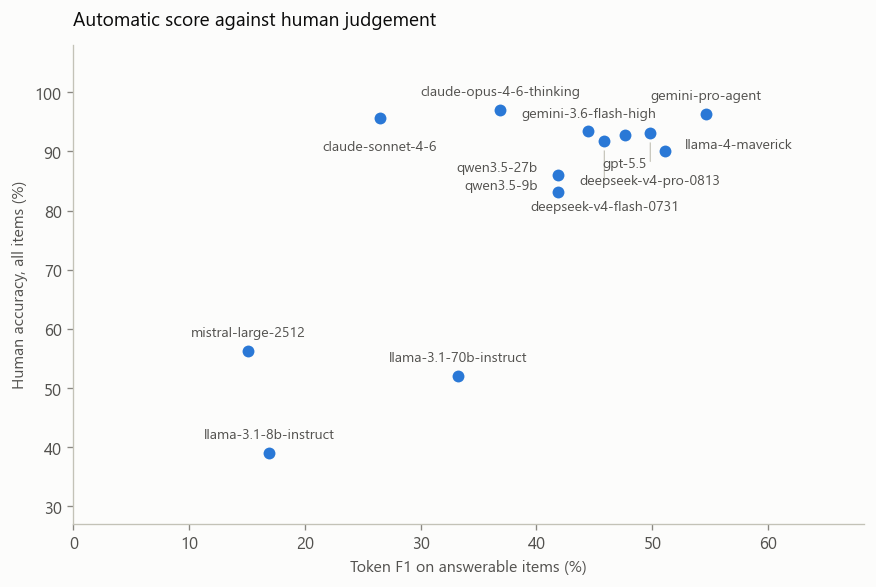

Reading: Spearman rank correlation = 0.45.
Best by Token F1:       gemini-pro-agent
Best by human accuracy: claude-opus-4-6-thinking

The two criteria disagree at the top. claude-opus-4-6-thinking is ranked 9th by Token F1
(36.8) yet first on human accuracy (97.0%) — it is judged correct and grounded
while phrasing answers that share few tokens with the reference. Reporting Token F1 alone would
invert this ranking, which is the argument for the human annotation layer.


In [ ]:
# --- Figure 3: does Token F1 rank models the way humans do? -----------------
x = comparison["token_f1"].to_numpy()
yv = comparison["human_accuracy"].to_numpy()

fig, ax = plt.subplots(figsize=(7.4, 5.0))
ax.scatter(x, yv, s=80, color=SERIES_1, edgecolor=SURFACE, linewidth=1.8, zorder=3)
ax.set_xlim(0, max(x) * 1.25)
ax.set_ylim(min(yv) - 12, 108)
label_points(ax, x, yv, [short_name(m) for m in comparison["model"]])
style(ax, "Automatic score against human judgement",
      "Token F1 on answerable items (%)", "Human accuracy, all items (%)", axis="both")
plt.tight_layout(); plt.show()

spearman = comparison[["token_f1", "human_accuracy"]].corr(method="spearman").iat[0, 1]
by_f1 = comparison.sort_values("token_f1", ascending=False)["model"].tolist()
by_hum = comparison.sort_values("human_accuracy", ascending=False)["model"].tolist()
print(f"Reading: Spearman rank correlation = {spearman:.2f}.")
print(f"Best by Token F1:       {short_name(by_f1[0])}")
print(f"Best by human accuracy: {short_name(by_hum[0])}")
if by_f1[0] != by_hum[0]:
    r = comparison.set_index("model").loc[by_hum[0]]


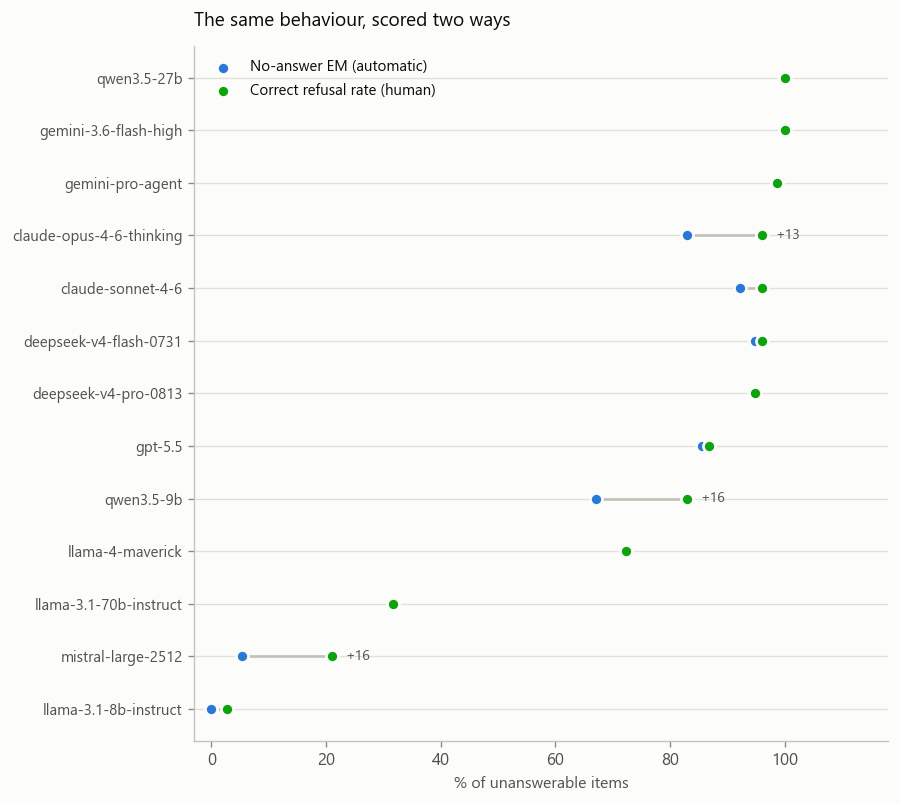

Reading: for 3 of 13 models the human rate exceeds No-answer EM by 5 points or more.
The largest gap is mistral-large-2512: 5% by the metric, 21% by human judgement.
Those models decline in their own words instead of emitting the exact UNANSWERABLE token, so
No-answer EM scores them as failures. It measures format compliance as much as refusal ability —
a limitation to state explicitly when reporting it.


In [ ]:
# --- Figure 4: No-answer EM measures format, not refusal ability ------------
comp = comparison.sort_values("correct_refusal_rate")
y = np.arange(len(comp))
a = comp["noans_em"].to_numpy()          # automatic: exact "UNANSWERABLE" string
b = comp["correct_refusal_rate"].to_numpy()   # human: did it actually decline?

fig, ax = plt.subplots(figsize=(7.6, 0.40 * N_MODELS + 1.6))
ax.hlines(y, a, b, color=AXIS, linewidth=1.6, zorder=2)
ax.scatter(a, y, s=52, color=SERIES_1, edgecolor=SURFACE, linewidth=1.6,
           zorder=3, label="No-answer EM (automatic)")
ax.scatter(b, y, s=52, color=GOOD, edgecolor=SURFACE, linewidth=1.6,
           zorder=3, label="Correct refusal rate (human)")
for yi, av, bv in zip(y, a, b):
    if abs(bv - av) >= 5:
        ax.annotate(f"+{bv - av:.0f}", (max(av, bv), yi), xytext=(8, 0),
                    textcoords="offset points", va="center", fontsize=8.5, color=INK_2)
ax.set_yticks(y, [short_name(m) for m in comp["model"]], fontsize=9)
ax.set_xlim(-3, 118)
ax.legend(loc="upper left", fontsize=9, bbox_to_anchor=(0.0, 1.0))
style(ax, "The same behaviour, scored two ways", "% of unanswerable items", axis="x")
plt.tight_layout(); plt.show()

gap = (comp["correct_refusal_rate"] - comp["noans_em"])
worst = comp.loc[gap.idxmax()]


## 4. Single-model profile

The cross-model view hides what an individual model's errors look like. This section
profiles `FOCUS` (set in the loading cell above).

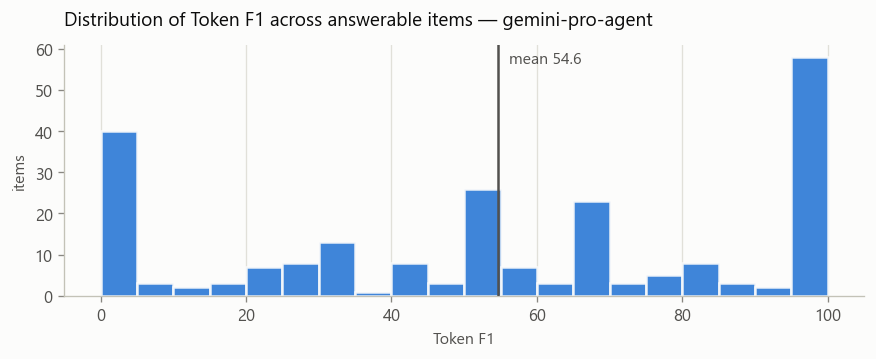

Reading: 40 of 226 answerable items score exactly 0, 58 score exactly 100, and 105 land between 20 and 80.
The mean of 54.6 sits between two clusters rather than describing a typical item, so it
belongs in the paper next to this distribution, not on its own.


In [ ]:
# --- Figure 5: the distribution behind the mean -----------------------------
item = raw[FOCUS]
short = item[item["qa_subtype"].eq(ST_SHORT)]
scores = short["token_f1"].dropna()

fig, ax = plt.subplots(figsize=(7.4, 3.1))
ax.hist(scores, bins=np.arange(0, 105, 5), color=SERIES_1, alpha=0.9,
        edgecolor=SURFACE, linewidth=1.5)
ax.axvline(scores.mean(), color=INK_2, linewidth=1.5, zorder=3)
ax.annotate(f"mean {scores.mean():.1f}", (scores.mean(), ax.get_ylim()[1] * 0.93),
            xytext=(7, 0), textcoords="offset points", fontsize=9.5, color=INK_2)
style(ax, f"Distribution of Token F1 across answerable items — {FOCUS}",
      "Token F1", "items")
plt.tight_layout(); plt.show()

zero = int((scores == 0).sum())
perfect = int((scores == 100).sum())
mid = int(((scores > 20) & (scores < 80)).sum())

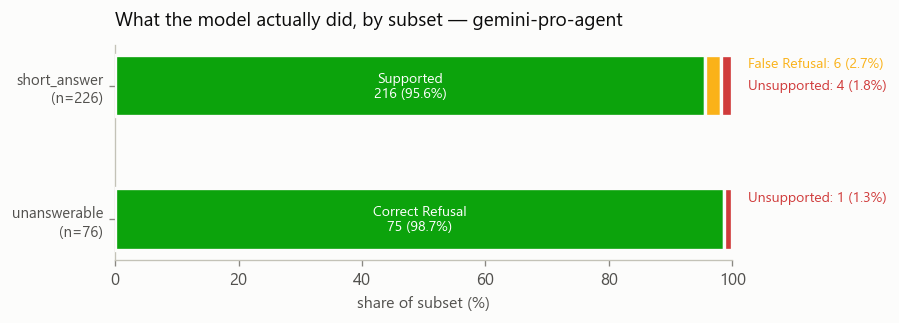

Reading: 98.7% of unanswerable items correctly refused, against 2.6% of answerable
items refused unnecessarily. Hallucination 1.77%, degenerate output 0.00%.


In [ ]:
# --- Figure 6: outcome composition by subset --------------------------------
item = raw[FOCUS]
fig, ax = plt.subplots(figsize=(7.6, 2.8))
rows = [(ST_UNANS, [LBL_CORRECT_REFUSAL, LBL_FALSE_REFUSAL, LBL_DEGENERATE,
                    LBL_UNSUPPORTED, LBL_SUPPORTED]),
        (ST_SHORT, [LBL_SUPPORTED, LBL_FALSE_REFUSAL, LBL_DEGENERATE,
                    LBL_UNSUPPORTED, LBL_CORRECT_REFUSAL])]
ticks = []
for i, (subtype, order) in enumerate(rows):
    sub = item[item["qa_subtype"].eq(subtype)]
    ticks.append(f"{subtype}\n(n={len(sub)})")
    left, outside = 0.0, []
    for lbl in order:
        n = int(sub["hallucination_type"].eq(lbl).sum())
        if not n:
            continue
        pct = 100 * n / len(sub)
        ax.barh(i, pct, left=left, height=0.46, color=OUTCOME_COLOR[lbl],
                edgecolor=SURFACE, linewidth=2, zorder=3)   # 2px surface gap
        if pct >= 12:
            ax.annotate(f"{lbl}\n{n} ({pct:.1f}%)", (left + pct / 2, i), ha="center",
                        va="center", fontsize=8.5, color="#ffffff", zorder=4)
        else:
            outside.append((lbl, n, pct))
        left += pct
    # Small segments get stacked labels to the right so they cannot collide.
    for k, (lbl, n, pct) in enumerate(outside):
        ax.annotate(f"{lbl}: {n} ({pct:.1f}%)", (101, i),
                    xytext=(6, 13 - 13 * k), textcoords="offset points",
                    va="center", fontsize=8.5, color=OUTCOME_COLOR[lbl],
                    annotation_clip=False)

ax.set_yticks(range(len(rows)), ticks, fontsize=9)
ax.set_xlim(0, 100)
style(ax, f"What the model actually did, by subset — {FOCUS}",
      "share of subset (%)", axis="x")
plt.tight_layout(); plt.show()

r = comparison.set_index("model").loc[FOCUS]


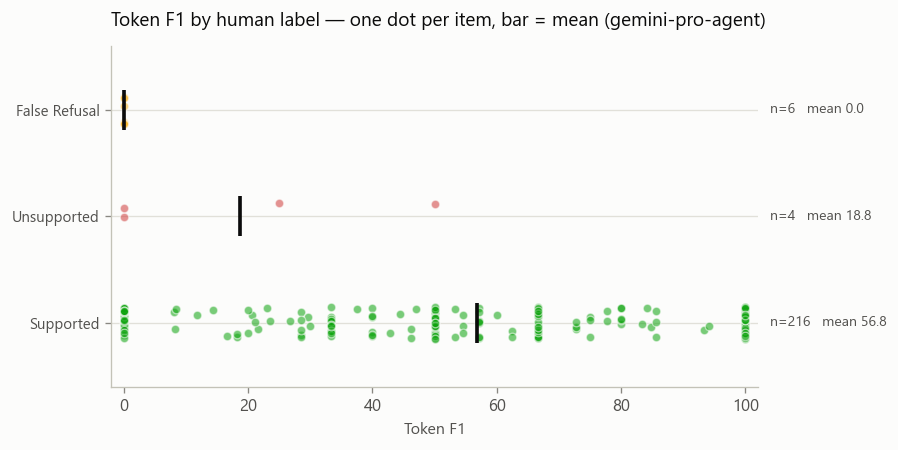

Reading: 54 of 216 items humans judged Supported score under 30 on Token F1 — correct,
grounded answers that share few tokens with the reference, which is what Sinhala paraphrase and
inflection do to an overlap metric. Automatic scores are a lower bound on quality, not a substitute
for the labels. With Unsupported at n=4 for this model, a correlation between the two is not
worth computing at the item level.


In [ ]:
# --- Figure 7: automatic score by human label -------------------------------
item = raw[FOCUS]
short = item[item["qa_subtype"].eq(ST_SHORT)]
groups = [(lbl, short.loc[short["hallucination_type"].eq(lbl), "token_f1"].dropna())
          for lbl in [LBL_SUPPORTED, LBL_UNSUPPORTED, LBL_DEGENERATE, LBL_FALSE_REFUSAL]]
groups = [(lbl, s) for lbl, s in groups if len(s)]

fig, ax = plt.subplots(figsize=(7.6, 0.75 * len(groups) + 1.6))
rng = np.random.default_rng(0)
for i, (lbl, s) in enumerate(groups):
    ax.scatter(s, i + rng.uniform(-0.15, 0.15, len(s)), s=26,
               color=OUTCOME_COLOR[lbl], alpha=0.55, edgecolor=SURFACE,
               linewidth=0.8, zorder=3)
    ax.plot([s.mean()], [i], marker="|", markersize=24, markeredgewidth=2.2,
            color=INK, zorder=4)
    ax.annotate(f"n={len(s)}   mean {s.mean():.1f}", (104, i), va="center",
                fontsize=8.5, color=INK_2, annotation_clip=False)

ax.set_yticks(range(len(groups)), [lbl for lbl, _ in groups], fontsize=9)
ax.set_xlim(-2, 102)
ax.set_ylim(-0.6, len(groups) - 0.4)
style(ax, f"Token F1 by human label — one dot per item, bar = mean ({FOCUS})",
      "Token F1", axis="x")
plt.tight_layout(); plt.show()

sup = short.loc[short["hallucination_type"].eq(LBL_SUPPORTED), "token_f1"].dropna()
uns = short.loc[short["hallucination_type"].eq(LBL_UNSUPPORTED), "token_f1"].dropna()
low = int((sup < 30).sum())

In [ ]:
# --- Limitations that depend on the data, checked rather than asserted ------
print("LABEL COVERAGE (every item must carry a human label)\n" + "-" * 62)
for m, d in raw.items():
    blank = int(d["hallucination_type"].eq("").sum())
    flag = "" if blank == 0 else f"   <-- {blank} UNLABELLED"
    print(f"{m[:34]:34} {len(d) - blank}/{len(d)} labelled{flag}")

print("\n\nANNOTATOR COVERAGE\n" + "-" * 62)
any_overlap = False
for m, d in raw.items():
    if "annotator_id" not in d.columns:
        continue
    per_item = d.groupby("id")["annotator_id"].nunique()
    dbl = int((per_item > 1).sum())
    any_overlap |= dbl > 0
    counts = d["annotator_id"].value_counts().to_dict()
    conf = d.groupby("annotator_id")["qa_subtype"].apply(
        lambda s: round(100 * s.eq(ST_UNANS).mean(), 1)).to_dict()
    named = int(d["annotator_id"].notna().sum())
    gap = "" if named == len(d) else f"  ({len(d) - named} rows have no annotator_id)"
    print(f"{m[:34]:34} items/annotator={counts}  %unanswerable={conf}  "
          f"doubly annotated={dbl}{gap}")


print("SMALL CLASSES (a rate on a handful of items is not stable)\n" + "-" * 62)
for m, d in raw.items():
    lab = d["hallucination_type"]
    n_h = int(lab.eq(LBL_UNSUPPORTED).sum())
    n_d = int(lab.eq(LBL_DEGENERATE).sum())
    if n_h <= 10 or n_d:
        print(f"{m[:34]:34} Unsupported n={n_h:>3}   Degenerate n={n_d:>3}")

LABEL COVERAGE (every item must carry a human label)
--------------------------------------------------------------
claude-opus-4-6-thinking           302/302 labelled
claude-sonnet-4-6                  302/302 labelled
deepseek/deepseek-v4-flash-0731    302/302 labelled
deepseek/deepseek-v4-pro-0813      302/302 labelled
gemini-pro-agent                   302/302 labelled
gemini-3.6-flash-high              302/302 labelled
gpt-5.5                            302/302 labelled
meta-llama/llama-3.1-70b-instruct  302/302 labelled
meta-llama/llama-3.1-8b-instruct   302/302 labelled
meta-llama/llama-4-maverick        302/302 labelled
mistralai/mistral-large-2512       302/302 labelled
qwen/qwen3.5-27b                   302/302 labelled
qwen/qwen3.5-9b                    302/302 labelled


ANNOTATOR COVERAGE
--------------------------------------------------------------
claude-opus-4-6-thinking           items/annotator={'BM': 152, 'DK': 150}  %unanswerable={'BM': 49.3, 'DK': 0.7}  doubly ann